# 1. Preprocesamiento y reducción de dimensionalidad

En este notebook armamos el pipeline de preprocesamiento con la estrategia de imputación que salió del EDA y miramos cuántas columnas produce. Con ese resultado probamos PCA y UMAP, y después varios selectores de variables, para decidir si conviene quedarnos con el pipeline completo o si reducir o seleccionar variables mejora de verdad el modelo.

In [1]:
import sys
from pathlib import Path

raiz = Path.cwd().resolve()
candidatas_raiz = [raiz, *raiz.parents]

# En Colab el repositorio puede estar en /content/<nombre-repo>, no en el CWD.
for base in (Path("/content"), Path("/workspace"), Path("/mnt/data")):
    if base.is_dir():
        candidatas_raiz.extend(hijo for hijo in base.iterdir() if hijo.is_dir())

for candidato in candidatas_raiz:
    if (candidato / "src").is_dir() and (candidato / "notebooks").is_dir():
        sys.path.insert(0, str(candidato))
        break

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.decomposition import PCA
from sklearn.feature_selection import RFE, SelectFromModel
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.model_selection import cross_validate

try:
    import umap
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "umap-learn"])
    import umap

from src.comun import (
    SEED,
    DIR_FIGS,
    DIR_TABLAS,
    guardar,
    exportar,
    guardar_estado,
    cargar_estado,
    configurar_columnas,
    construir_preprocesador,
    UMAPTransformer,
)

globals().update(cargar_estado("1_eda"))
configurar_columnas(all_num_features, all_cat_features, cols_na)

c:\Users\ASUS\Desktop\V8-final\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
print("=== 9.1 CONSTRUCCIÓN DEL PIPELINE DE PREPROCESAMIENTO ===")
estrategia_final = estrategia_recomendada
preprocesador = construir_preprocesador(estrategia_final)

X_train_prep = preprocesador.fit_transform(X_train)
print(f"Dimensiones originales de X_train: {X_train.shape}")
print(f"Dimensiones de X_train tras preprocesamiento (Imputación, Escalado y OneHotEncoding): {X_train_prep.shape}")

print("\n=== 9.2 EXTRACCIÓN LINEAL: PCA (Análisis de Componentes Principales) ===")
pca = PCA(n_components=0.95, random_state=SEED)
X_train_pca = pca.fit_transform(X_train_prep)

componentes_usados = pca.n_components_
varianza_explicada = pca.explained_variance_ratio_.sum() * 100
print(f"El PCA retuvo el {varianza_explicada:.2f}% de la información original usando {componentes_usados} componentes principales.")

print("\n=== 9.3 EXTRACCIÓN NO LINEAL: UMAP ===")
reductor_umap = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=SEED)
X_train_umap = reductor_umap.fit_transform(X_train_prep)
print("Proyección UMAP completada con éxito a 2 dimensiones (n_components=2).")

=== 9.1 CONSTRUCCIÓN DEL PIPELINE DE PREPROCESAMIENTO ===
Dimensiones originales de X_train: (4058, 18)
Dimensiones de X_train tras preprocesamiento (Imputación, Escalado y OneHotEncoding): (4058, 37)

=== 9.2 EXTRACCIÓN LINEAL: PCA (Análisis de Componentes Principales) ===
El PCA retuvo el 95.25% de la información original usando 19 componentes principales.

=== 9.3 EXTRACCIÓN NO LINEAL: UMAP ===


c:\Users\ASUS\Desktop\V8-final\.venv\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
c:\Users\ASUS\Desktop\V8-final\.venv\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Proyección UMAP completada con éxito a 2 dimensiones (n_components=2).


Después de imputar, escalar y aplicar one-hot, X_train pasó de 18 a 37 columnas. Para llegar al 95,25 % de la varianza el PCA necesitó 19 componentes, y el UMAP lo calculamos en dos dimensiones solo para poder visualizar los datos. Por ahora dejamos esta reducción documentada, pero el pipeline final sigue con las 37 columnas.

### 9.2–9.3 Visualización de PCA y UMAP

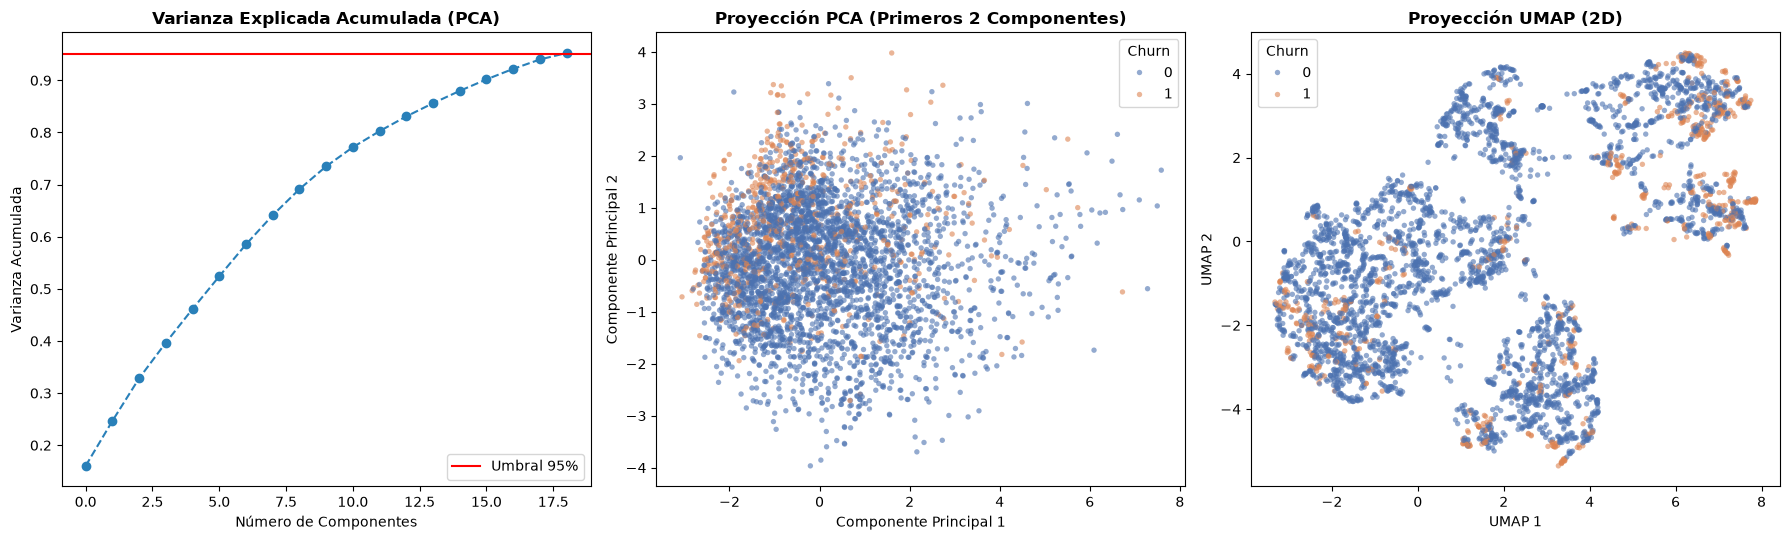

In [3]:
# Figura exploratoria 09: varianza acumulada de PCA, PCA 2D y UMAP 2D.
# Si esta celda se ejecuta aislada, recupera los objetos guardados.
if "X_train_pca" not in globals() or "y_train" not in globals():
    globals().update(cargar_estado("1_eda"))
    globals().update(cargar_estado("2_preprocessing"))

COLORES = {0: "#4c72b0", 1: "#dd8452"}

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# 1) Varianza explicada acumulada de PCA
axes[0].plot(np.cumsum(pca.explained_variance_ratio_), marker="o", linestyle="--", color="#2980b9")
axes[0].axhline(y=0.95, color="r", linestyle="-", label="Umbral 95%")
axes[0].set_title("Varianza Explicada Acumulada (PCA)", fontweight="bold")
axes[0].set_xlabel("Número de Componentes")
axes[0].set_ylabel("Varianza Acumulada")
axes[0].legend()

# 2) Proyección PCA 2D
sns.scatterplot(
    x=X_train_pca[:, 0], y=X_train_pca[:, 1], hue=y_train,
    palette=COLORES, alpha=0.6, s=15, edgecolor="none", ax=axes[1]
)
axes[1].set_title("Proyección PCA (Primeros 2 Componentes)", fontweight="bold")
axes[1].set_xlabel("Componente Principal 1")
axes[1].set_ylabel("Componente Principal 2")

# 3) Proyección UMAP 2D
sns.scatterplot(
    x=X_train_umap[:, 0], y=X_train_umap[:, 1], hue=y_train,
    palette=COLORES, alpha=0.6, s=15, edgecolor="none", ax=axes[2]
)
axes[2].set_title("Proyección UMAP (2D)", fontweight="bold")
axes[2].set_xlabel("UMAP 1")
axes[2].set_ylabel("UMAP 2")

plt.tight_layout()
guardar(fig, "09_reduccion_dimensionalidad")
plt.show()

En la curva de varianza acumulada se ve que con 19 componentes ya pasamos el 95 %. Las proyecciones en 2D de PCA y UMAP son solo exploratorias: no reemplazan la evaluación con los modelos, que es donde tomamos las decisiones. Más adelante comparamos la reducción con 23 componentes como presupuesto fijo, y dejamos los 19 como referencia.

# 2 Selección de variables y candidatas a eliminar

In [4]:
from sklearn.feature_selection import RFE, SelectFromModel
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.base import clone

candidatas_auto = assoc[assoc["tamaño_efecto"].abs() < 0.12].index.tolist()
candidatas = sorted(set(candidatas_auto + ["CashbackAmount"]))
tabla_candidatas = assoc.loc[candidatas, ["naturaleza", "tamaño_efecto", "q_BH"]].copy()
tabla_candidatas["motivo"] = "efecto bajo o redundancia con PreferedOrderCat"
display(tabla_candidatas.round(4))
exportar(tabla_candidatas.round(4), "09_4_variables_candidatas")

base_hgb = HistGradientBoostingClassifier(max_iter=300, random_state=SEED)
base_rf = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced_subsample",
    random_state=SEED,
    n_jobs=1,
)
selectores = {
    "RFE-8": RFE(LogisticRegression(C=0.1, class_weight="balanced", max_iter=3000), n_features_to_select=8),
    "RFE-13": RFE(LogisticRegression(C=0.1, class_weight="balanced", max_iter=3000), n_features_to_select=13),
    "RFE-18": RFE(LogisticRegression(C=0.1, class_weight="balanced", max_iter=3000), n_features_to_select=18),
    "RFE-25": RFE(LogisticRegression(C=0.1, class_weight="balanced", max_iter=3000), n_features_to_select=25),
    "L1 LinearSVC": SelectFromModel(
        LinearSVC(C=0.01, penalty="l1", dual=False, class_weight="balanced", max_iter=5000), threshold="median"
    ),
}

filas_fs = []
for nombre_sel, selector in selectores.items():
    for nombre_mdl, clf in {"HGB": base_hgb, "RF": base_rf}.items():
        pipe = Pipeline([
            ("prep", construir_preprocesador(estrategia_final)),
            ("fs", clone(selector)),
            ("clf", clone(clf)),
        ])
        r = cross_validate(
            pipe, X_train, y_train, cv=CV_TUNING,
            scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc"},
            n_jobs=-1,
            return_train_score=True,
        )
        filas_fs.append({
            "Selector": nombre_sel,
            "Modelo": nombre_mdl,
            "PR-AUC val": r["test_pr_auc"].mean(),
            "PR-AUC val std": r["test_pr_auc"].std(),
            "PR-AUC train": r["train_pr_auc"].mean(),
            "Brecha": r["train_pr_auc"].mean() - r["test_pr_auc"].mean(),
            "ROC-AUC val": r["test_roc_auc"].mean(),
        })

df_fs = pd.DataFrame(filas_fs).sort_values(["Modelo", "PR-AUC val"], ascending=[True, False])
display(df_fs.round(4))
exportar(df_fs.round(4), "09_4_seleccion_variables_group_cv")


,naturaleza,tamaño_efecto,q_BH,motivo
variable,,,,
CashbackAmount,Continua,-0.254,0.0000,efecto bajo o redundancia con PreferedOrderCat
CityTier,Categórica/Ordinal,0.094,0.0000,efecto bajo o redundancia con PreferedOrderCat
CouponUsed,Discreta (Conteo),-0.001,0.9772,efecto bajo o redundancia con PreferedOrderCat
Gender,Categórica/Ordinal,0.032,0.0571,efecto bajo o redundancia con PreferedOrderCat
HourSpendOnApp,Discreta (Conteo),0.007,0.8273,efecto bajo o redundancia con PreferedOrderCat
NumberOfAddress,Discreta (Conteo),0.078,0.0079,efecto bajo o redundancia con PreferedOrderCat
OrderAmountHikeFromlastYear,Discreta (Conteo),-0.072,0.0151,efecto bajo o redundancia con PreferedOrderCat
OrderCount,Discreta (Conteo),-0.010,0.8044,efecto bajo o redundancia con PreferedOrderCat
PreferredLoginDevice,Categórica/Ordinal,0.046,0.0093,efecto bajo o redundancia con PreferedOrderCat


,Selector,Modelo,PR-AUC val,PR-AUC val std,PR-AUC train,Brecha,ROC-AUC val
6,RFE-25,HGB,0.8632,0.0155,1.0000,0.1368,0.9538
8,L1 LinearSVC,HGB,0.8418,0.0163,1.0000,0.1582,0.9470
4,RFE-18,HGB,0.8251,0.0193,0.9993,0.1742,0.9421
2,RFE-13,HGB,0.7801,0.0287,0.9931,0.2130,0.9249
0,RFE-8,HGB,0.6378,0.0492,0.8941,0.2563,0.8651
7,RFE-25,RF,0.8312,0.0285,1.0000,0.1688,0.9495
9,L1 LinearSVC,RF,0.8303,0.0312,1.0000,0.1697,0.9461
5,RFE-18,RF,0.7902,0.0342,0.9983,0.2081,0.9377
3,RFE-13,RF,0.7391,0.0351,0.9856,0.2465,0.9179
1,RFE-8,RF,0.6213,0.0251,0.8760,0.2547,0.8736


Entre los selectores, RFE con 25 variables fue el mejor, con un PR-AUC de 0,863 en HGB y 0,831 en Random Forest, seguido por L1 con 0,842 y 0,830. En el otro extremo, RFE con 8 variables cayó a 0,638 y 0,621. Ninguno superó a los modelos con todas las variables (0,874 con HGB y 0,835 con Random Forest en los notebooks siguientes), así que no vemos razón para usar un selector automático y nos quedamos con las 37 columnas.

In [6]:
guardar_estado("2_preprocessing",
    estrategia_final=estrategia_final,
    preprocesador=preprocesador,
    X_train_prep=X_train_prep,
    X_train_pca=X_train_pca,
    X_train_umap=X_train_umap,
    pca=pca,
    reductor_umap=reductor_umap,
    varianza_explicada=varianza_explicada,
    componentes_usados=componentes_usados,
)


WindowsPath('C:/Users/ASUS/Desktop/V8-final/data/processed/estado_2_preprocessing.joblib')

Al final guardamos el pipeline ajustado, las matrices procesadas y los resultados de PCA (19 componentes) y UMAP, y exportamos las tablas de selección a reports/. La decisión de este notebook es mantener el pipeline completo, sin reducción ni selección automática. La comparación de reducción con los modelos la dejamos para 5_pca_umap.